# Actividad: diseñar un pool para un crawler

**Enunciado**
- 1000 URLs; cada request tarda 50–500 ms.
- La API externa permite **20 requests simultáneos**.
- Cada respuesta necesita parseo liviano.
- Diseñar tamaño de pool, cola y estrategia de timeout.
- Agregar métricas que miraríamos durante la prueba.




In [ ]:
import time, random, threading, queue, re, statistics
from collections import defaultdict
import matplotlib.pyplot as plt

API_LIMIT = 20   # límite de la API externa

class RateLimited(Exception): pass

class FakeAPI:
    def __init__(self, limit=API_LIMIT, fail_rate=0.02, hang_rate=0.01):
        self.limit, self.fail_rate, self.hang_rate = limit, fail_rate, hang_rate
        self._lock = threading.Lock()
        self.in_flight = 0
        self.max_in_flight = 0
        self.rejected = 0

    def get(self, url, timeout):
        with self._lock:
            if self.in_flight >= self.limit:
                self.rejected += 1
                raise RateLimited("429 Too Many Requests")
            self.in_flight += 1
            self.max_in_flight = max(self.max_in_flight, self.in_flight)
        try:
            latency = random.uniform(0.05, 0.5)
            if random.random() < self.hang_rate:
                latency = 5.0                      # request colgado
            if latency > timeout:
                time.sleep(timeout)
                raise TimeoutError(f"timeout {url}")
            time.sleep(latency)
            if random.random() < self.fail_rate:
                raise ConnectionError(f"error de conexión {url}")
            return f"<html><title>Pagina {url}</title><a href='/a'>a</a><a href='/b'>b</a></html>"
        finally:
            with self._lock:
                self.in_flight -= 1

TITLE_RE = re.compile(r"<title>(.*?)</title>", re.S)
LINK_RE  = re.compile(r"href='(.*?)'")

def parse(html):
    m = TITLE_RE.search(html)
    return {"title": m.group(1) if m else None, "links": LINK_RE.findall(html)}


In [ ]:
class Metrics:
    def __init__(self):
        self.lock = threading.Lock()
        self.latencies = []      # duración total por URL (incluye reintentos)
        self.queue_waits = []    # tiempo esperando en cola
        self.ok = self.failed = self.retries = 0
        self.errors = defaultdict(int)
        self.active = 0
        self.samples = []        # (t, queue_depth, active_workers)

def run_crawler(urls, api, n_workers=20, queue_size=40, timeout=1.0,
                max_retries=2, backoff=0.1, sample_every=0.1):
    q = queue.Queue(maxsize=queue_size)     # COLA ACOTADA -> backpressure
    m = Metrics()
    results = {}
    STOP = object()
    t0 = time.perf_counter()

    def fetch_with_retries(url):
        for attempt in range(max_retries + 1):
            try:
                return api.get(url, timeout)
            except (TimeoutError, ConnectionError, RateLimited) as e:
                with m.lock:
                    m.errors[type(e).__name__] += 1
                if attempt == max_retries:
                    raise
                with m.lock:
                    m.retries += 1
                time.sleep(backoff * (2 ** attempt) * random.uniform(0.5, 1.5))  # backoff + jitter

    def worker():
        while True:
            item = q.get()
            if item is STOP:
                q.task_done()
                return
            url, t_enq = item
            start = time.perf_counter()
            with m.lock:
                m.queue_waits.append(start - t_enq)
                m.active += 1
            try:
                html = fetch_with_retries(url)
                results[url] = parse(html)
                with m.lock:
                    m.ok += 1
            except Exception:
                with m.lock:
                    m.failed += 1
            finally:
                with m.lock:
                    m.active -= 1
                    m.latencies.append(time.perf_counter() - start)
                q.task_done()

    stop_monitor = threading.Event()
    def monitor():
        while not stop_monitor.is_set():
            with m.lock:
                m.samples.append((time.perf_counter() - t0, q.qsize(), m.active))
            time.sleep(sample_every)

    threads = [threading.Thread(target=worker, daemon=True) for _ in range(n_workers)]
    mon = threading.Thread(target=monitor, daemon=True)
    for t in threads: t.start()
    mon.start()

    for url in urls:                      # el productor se bloquea si la cola está llena
        q.put((url, time.perf_counter()))
    for _ in threads:
        q.put(STOP)
    for t in threads: t.join()
    stop_monitor.set(); mon.join()

    total = time.perf_counter() - t0
    return results, m, total

def pct(data, p):
    if not data: return float("nan")
    data = sorted(data)
    return data[min(len(data) - 1, int(len(data) * p / 100))]

def report(label, m, total, api, n_urls):
    print(f"=== {label} ===")
    print(f"Tiempo total        : {total:.1f} s")
    print(f"Throughput          : {n_urls / total:.1f} req/s")
    print(f"OK / Fallidos       : {m.ok} / {m.failed}")
    print(f"Reintentos          : {m.retries}")
    print(f"Errores por tipo    : {dict(m.errors)}")
    print(f"Latencia p50/p95/p99: {pct(m.latencies,50)*1000:.0f} / {pct(m.latencies,95)*1000:.0f} / {pct(m.latencies,99)*1000:.0f} ms")
    print(f"Espera en cola media: {statistics.mean(m.queue_waits)*1000:.0f} ms")
    print(f"Máx en vuelo (API)  : {api.max_in_flight}  (límite {api.limit})")
    print(f"Rechazos 429        : {api.rejected}")
    print()


## 2. Ejecución (20 workers, cola 40, timeout 1 s)

In [ ]:
URLS = [f"https://ejemplo.com/pagina/{i}" for i in range(1000)]

api = FakeAPI()
results, metrics, total = run_crawler(URLS, api, n_workers=20, queue_size=40,
                                      timeout=1.0, max_retries=2)
report("Diseño propuesto", metrics, total, api, len(URLS))
print("Páginas parseadas:", len(results))


=== Diseño propuesto ===
Tiempo total        : 15.4 s
Throughput          : 64.8 req/s
OK / Fallidos       : 1000 / 0
Reintentos          : 29
Errores por tipo    : {'ConnectionError': 19, 'TimeoutError': 10}
Latencia p50/p95/p99: 287 / 491 / 1158 ms
Espera en cola media: 594 ms
Máx en vuelo (API)  : 20  (límite 20)
Rechazos 429        : 0

Páginas parseadas: 1000


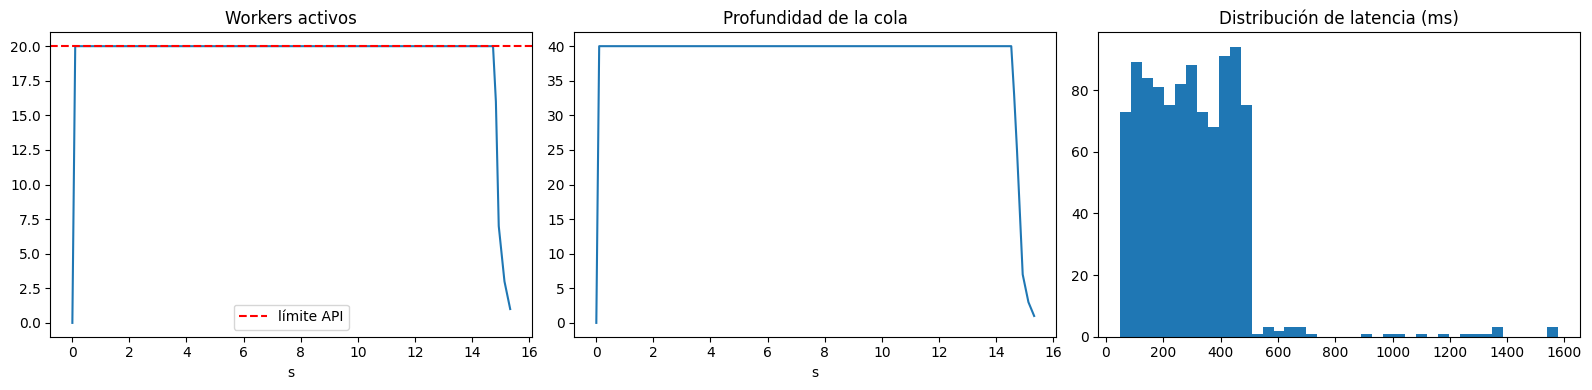

In [ ]:
# Gráficos de las métricas durante la prueba
ts = [s[0] for s in metrics.samples]
qd = [s[1] for s in metrics.samples]
ac = [s[2] for s in metrics.samples]

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].plot(ts, ac); axs[0].axhline(API_LIMIT, color="r", ls="--", label="límite API")
axs[0].set_title("Workers activos"); axs[0].set_xlabel("s"); axs[0].legend()
axs[1].plot(ts, qd); axs[1].set_title("Profundidad de la cola"); axs[1].set_xlabel("s")
axs[2].hist([l*1000 for l in metrics.latencies], bins=40)
axs[2].set_title("Distribución de latencia (ms)")
plt.tight_layout(); plt.show()


## 3. Experimento: ¿qué pasa si cambiamos el tamaño del pool?
Usamos 200 URLs para que sea rápido.

=== 5 workers ===
Tiempo total        : 11.8 s
Throughput          : 16.9 req/s
OK / Fallidos       : 200 / 0
Reintentos          : 4
Errores por tipo    : {'ConnectionError': 4}
Latencia p50/p95/p99: 293 / 474 / 655 ms
Espera en cola media: 608 ms
Máx en vuelo (API)  : 5  (límite 20)
Rechazos 429        : 0

=== 10 workers ===
Tiempo total        : 6.0 s
Throughput          : 33.2 req/s
OK / Fallidos       : 200 / 0
Reintentos          : 5
Errores por tipo    : {'ConnectionError': 5}
Latencia p50/p95/p99: 285 / 484 / 799 ms
Espera en cola media: 553 ms
Máx en vuelo (API)  : 10  (límite 20)
Rechazos 429        : 0

=== 20 workers ===
Tiempo total        : 3.2 s
Throughput          : 62.4 req/s
OK / Fallidos       : 200 / 0
Reintentos          : 3
Errores por tipo    : {'ConnectionError': 3}
Latencia p50/p95/p99: 281 / 480 / 604 ms
Espera en cola media: 474 ms
Máx en vuelo (API)  : 20  (límite 20)
Rechazos 429        : 0

=== 30 workers ===
Tiempo total        : 2.7 s
Throughput        

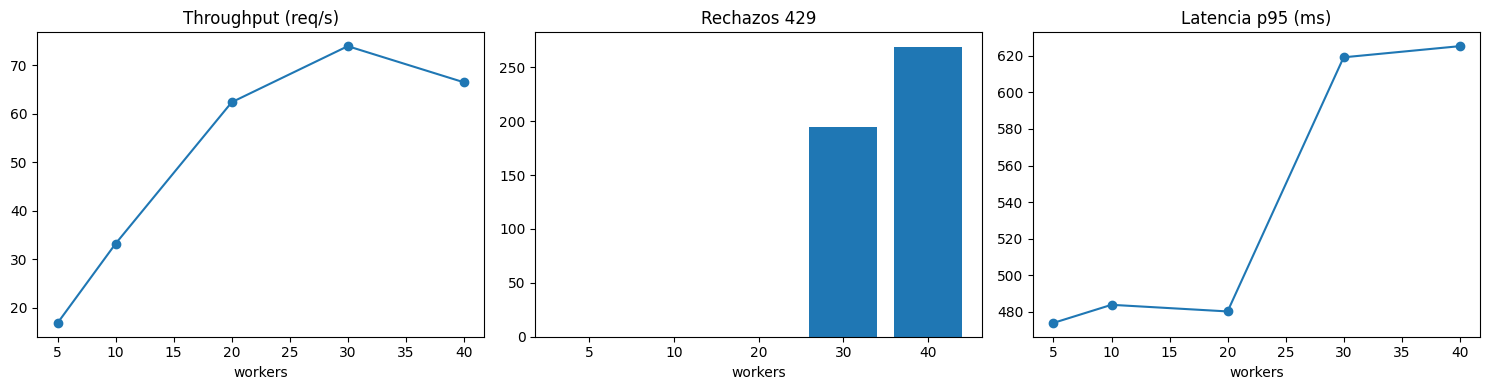

In [ ]:
sweep = []
for n in [5, 10, 20, 30, 40]:
    api_i = FakeAPI()
    _, m_i, t_i = run_crawler(URLS[:200], api_i, n_workers=n, queue_size=2*n)
    report(f"{n} workers", m_i, t_i, api_i, 200)
    sweep.append((n, 200 / t_i, api_i.rejected, m_i.failed, pct(m_i.latencies, 95)*1000))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
ns = [s[0] for s in sweep]
axs[0].plot(ns, [s[1] for s in sweep], marker="o"); axs[0].set_title("Throughput (req/s)")
axs[1].bar([str(n) for n in ns], [s[2] for s in sweep]); axs[1].set_title("Rechazos 429")
axs[2].plot(ns, [s[4] for s in sweep], marker="o"); axs[2].set_title("Latencia p95 (ms)")
for a in axs: a.set_xlabel("workers" if a is not axs[1] else "workers")
plt.tight_layout(); plt.show()


## 4. Experimento: cola acotada vs. el productor
Con `queue_size` chico el productor se bloquea y la memoria queda controlada. Probá cambiar `queue_size` (1, 40, 1000) en la sección 2 y mirá el gráfico de profundidad de cola.

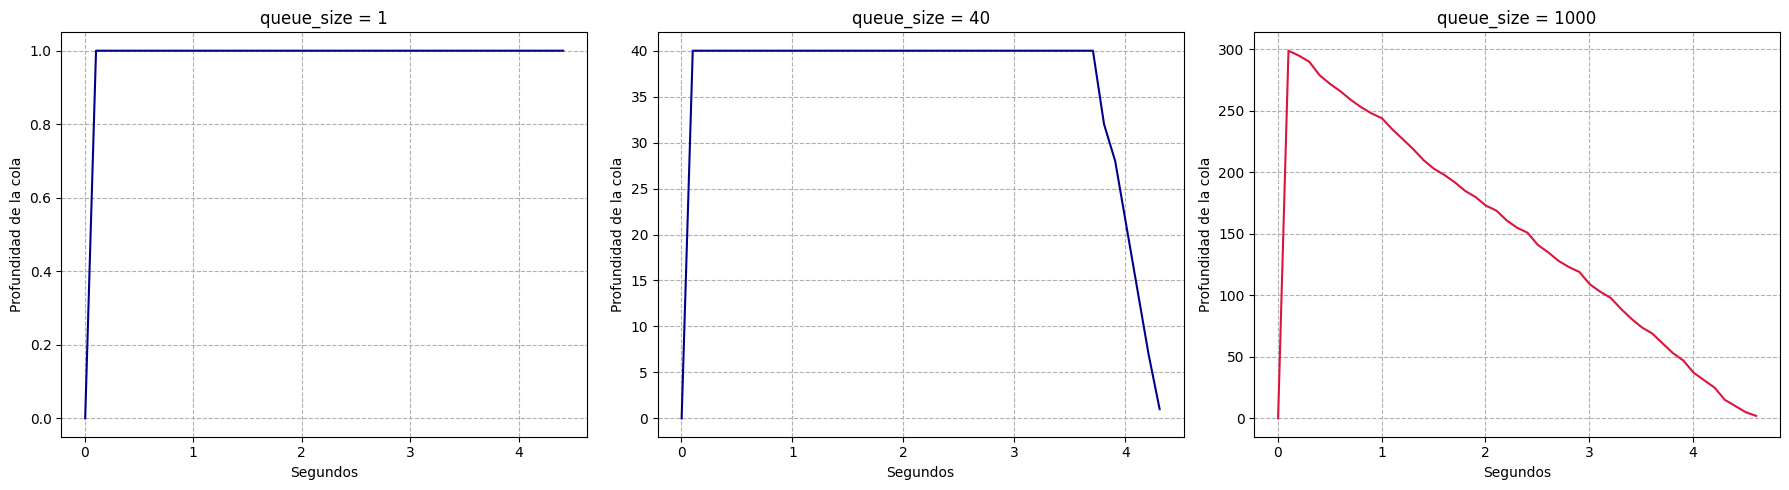

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
sizes = [1, 40, 1000]

for i, q_size in enumerate(sizes):
    api_exp = FakeAPI()
    # Usamos 300 URLs para poder apreciar con claridad el comportamiento de la cola en el tiempo
    _, m_exp, _ = run_crawler(URLS[:300], api_exp, n_workers=20, queue_size=q_size, timeout=1.0, max_retries=2)

    ts_exp = [s[0] for s in m_exp.samples]
    qd_exp = [s[1] for s in m_exp.samples]

    axs[i].plot(ts_exp, qd_exp, label=f'Cola (size={q_size})', color='darkblue' if q_size != 1000 else 'crimson')
    axs[i].set_title(f"queue_size = {q_size}")
    axs[i].set_xlabel("Segundos")
    axs[i].set_ylabel("Profundidad de la cola")
    axs[i].grid(True, linestyle='--')

plt.tight_layout()
plt.show()

## 5. Conclusiones del Experimento

A partir de las pruebas y simulaciones realizadas, podemos extraer las siguientes conclusiones sobre el comportamiento de nuestro crawler concurrente:

* **El tamaño del Pool de Workers:** Establecer el límite en 20 threads es la opción óptima. Dado que la API externa restringe los accesos a un máximo de 20 peticiones simultáneas, incrementar el número de workers por encima de este valor no mejora el rendimiento. Al contrario, genera saturación, desencadena errores de límite de tasa (peticiones rechazadas con código 429) y degrada la latencia general debido al tiempo desperdiciado en reintentos y esperas de backoff.

* **La importancia de la Cola Acotada (queue_size):** El tamaño de la cola es el mecanismo de control de flujo esencial (*backpressure*).
  * Con un `queue_size` extremadamente bajo (como 1), el productor se bloquea casi de inmediato, enviando elementos solo al ritmo en que los workers se liberan, manteniendo la memoria al mínimo absoluto.
  * Con un tamaño balanceado de 40, la cola absorbe ráfagas sin sobrecargar el sistema.
  * Si la cola no tiene límite o es excesivamente grande (como 1000), el productor encola todo el trabajo instantáneamente. Aunque el crawler termine de procesar en tiempos similares, esto provoca un pico innecesario en el consumo de memoria para almacenar las tareas pendientes, lo que en sistemas reales con millones de URLs causaría un colapso por falta de memoria (Out of Memory).

* **Gestión de Timeout y Reintentos:** Un timeout de 1 segundo es adecuado porque cubre holgadamente la latencia máxima habitual de la API (500 ms) sin penalizar en exceso cuando un request se queda colgado de forma anómala (los cuales simulan tardar 5 segundos). Implementar 2 reintentos con un esquema de *backoff exponencial* y *jitter* permite mitigar fallos de red esporádicos y caídas temporales de conexión sin saturar la API externa con una tormenta de peticiones concurrentes inmediatas.

* **Ubicación del Parseo:** Dado que el procesamiento del HTML descargado es una tarea muy liviana (búsquedas rápidas con expresiones regulares), ejecutarla directamente dentro del hilo del worker es la opción más eficiente y simple. Si en el futuro el procesamiento requiriera cálculos pesados o renderizado complejo, se debería delegar a un pool de procesos independiente (`ProcessPoolExecutor`) para no bloquear el bucle de entrada/salida de los hilos.

**Diseño:** La concurrencia eficiente no consiste en lanzar la mayor cantidad de hilos posibles, sino en definir límites explícitos y coordinados (pool, cola acotada y timeouts) para proteger tanto nuestros recursos de memoria como la disponibilidad del servicio externo.